# 🧪 المختبر 01 — الحركية الدوائية: من النظرية إلى الكود

> **«الكتاب الحي»** — مختبرات علم الأدوية العملية | دفتر Jupyter جاهز للتشغيل
> كل معادلة درستها نظرياً في الفصل 2 من الكتاب، ستحوّلها هنا إلى كود يُنفَّذ، ورسم بياني يُقرأ، وقرار إكليني يُتَّخذ.

| البند | التفاصيل |
|---|---|
| 📘 الفصل المرتبط | **الفصل 2: الحركية الدوائية (Pharmacokinetics)** — «ما يفعله الجسم بالدواء» |
| ⏱️ الزمن التقديري | 90 – 120 دقيقة |
| 📊 المستوى | مبتدئ → متوسط |
| 🛠️ المتطلبات | Python 3.9+ |
| 🎯 الناتج | 5 محاكاة حقيقية، 5 رسوم بيانية، قرارات إكلينية مبرمجة، تمارين محلولة |

### أهداف التعلّم
بعد إكمال هذا الدفتر ستكون قادراً على أن:
1. تترجم معادلات الحركية الدوائية الأساسية إلى دوال بايثون قابلة للمحاكاة.
2. تحسب $C_{max}$ و $T_{max}$ و $AUC$ برمجياً وتفسر معناها الإكليني.
3. تحاكي الجرعات المتكررة وتفهم التراكم (Accumulation) والحالة المستقرة (Steady State).
4. تحلل النافذة العلاجية وتكتب «دالة قرار» تُصنّف جدولاً جرعياً: آمن / يحتاج ضبطاً / سام.
5. تربط كل ذلك بحالات 2026 الحقيقية: **Orforglipron (Foundayo)** و **Enlicitide (Lipfendra)**.

> 💡 **فلسفة المختبر:** لا تحفظ المعادلة… بل نفّذها، عطّلها، عدّل بارامتراتها، وشاهد النتيجة. هذا هو الفرق بين من يقرأ الفارما ومن *يبرمجها*.

## 🚀 كيف تشغّل هذا الدفتر؟ (3 طرق)

**الطريقة 1 — محلياً (موصى بها):**
```bash
pip install numpy pandas matplotlib scipy jupyter arabic-reshaper python-bidi
jupyter notebook Lab01_Pharmacokinetics.ipynb
```

**الطريقة 2 — Google Colab:** ارفع الملف عبر `File → Upload Notebook`، ثم شغّل الخلايا بالترتيب. (الخط العربي Tajawal مرفق في مجلد `fonts/` — على Colab ستعمل الرسوم بالمصطلحات العلمية الإنجليزية تلقائياً).

**الطريقة 3 — VS Code:** افتح الملف وثبّت إضافة Python + Jupyter ثم `Run All`.

### 📝 ملاحظتان قبل البدء
1. **لغة الرسوم البيانية:** المحاور والمصطلحات التقنية تبقى بالصيغة العلمية المعيارية ($C_{max}$، $t_{1/2}$، $AUC$، µg/mL) لأنها لغة النشر الدوائي العالمي — بينما العناوين والشرح بالعربية عبر دالة `ar()` التي تشكّل الحروف صحيحاً إن توفّر خط عربي.
2. **الأرقام المرجعية:** بارامترات الأدوية قيم تقريبية من المراجع الدوائية القياسية لأغراض التعلّم؛ أي قرار حقيقي يحتاج مصادر رسمية وشروط مرضية فعلية.

---
## الجزء 1 — نموذج الحجرة الواحدة (IV Bolus)

عندما يُحقن دواء وريدياً (IV) مباشرة، يوزَّع فوراً في «حجرة» مركزية واحدة، ويبدأ الإطراح فوراً بعملية من الدرجة الأولى: **نسبة ثابتة** تُطرح في وحدة الزمن — وليس كمية ثابتة. هذا «الأُس السالب» هو سبب الشكل الأشهر في الفارما: منحنى التناقص الأسّي.

$$C(t) = C_0 \cdot e^{-kt}, \qquad C_0 = \frac{D}{V_d}, \qquad k = \frac{CL}{V_d} = \frac{\ln 2}{t_{1/2}}$$

| الرمز | المعنى | الوحدة | الترجمة البرمجية |
|---|---|---|---|
| $D$ | الجرعة | mg | `D` |
| $V_d$ | حجم التوزيع | L | `Vd = vd_kg * BW` |
| $k$ | ثابت الإطراح | h⁻¹ | `k = np.log(2)/thalf` |
| $CL$ | التصفية | L/h | `CL = k * Vd` |
| $t_{1/2}$ | نصف العمر | h | `thalf` |

> 🔑 **قاعدة ذهبية:** بعد كل نصف عمر يتبقى نصف الموجود: 100% ← 50% ← 25% ← 12.5%… وبعد **~5 أنصاف عمر** يتبقى أقل من 3% (أو بلغت الحالة المستقرة 97% في التجميع). هذه القاعدة وحدها تحكم مدة الغسيل، وتباعد الجرعات، وزمن انسحاب الدواء.

In [1]:
# ═══ الإعداد العام للمختبر ═══
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import os

# 1) الخط العربي — Tajawal مرفق مع الدفتر في مجلد fonts/
for f in ['fonts/Tajawal-Regular.ttf', 'fonts/Tajawal-Bold.ttf']:
    if os.path.exists(f):
        fm.fontManager.addfont(f)
HAS_AR = any('Tajawal' in f.name for f in fm.fontManager.ttflist)
plt.rcParams['font.sans-serif'] = (['Tajawal'] if HAS_AR else []) + ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 2) دالة تشكيل النص العربي في الرسوم (reshape + bidi)
try:
    import arabic_reshaper
    from bidi.algorithm import get_display
    def ar(txt):
        """يعيد النص العربي مشكّلاً صحيح الاتجاه إن توفر خط عربي، وإلا كما هو"""
        return get_display(arabic_reshaper.reshape(txt)) if HAS_AR else txt
except ImportError:
    def ar(txt):
        return txt

# 3) الهوية البصرية الموحدة للمختبر (لغة المحاور: الرموز العلمية المعيارية)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.titleweight': 'bold', 'axes.labelsize': 11,
                     'axes.titlesize': 12.5})
TEAL = ['#0F766E', '#0D9488', '#14B8A6', '#2DD4BF', '#F59E0B', '#E11D48']

print('✅ البيئة جاهزة | الخط العربي:', 'Tajawal ✔' if HAS_AR else 'غير متوفر → عناوين إنجليزية تلقائياً')


✅ البيئة جاهزة | الخط العربي: Tajawal ✔


In [2]:
# ═══ قاعدة بيانات الأدوية + مكتبة دوال النموذج ═══
# قيم مرجعية تقريبية من المراجع الدوائية القياسية (لأغراض التعليم)
DRUGS = pd.DataFrame([
    # الاسم، t½(h)، Vd(L/kg)، F، ka(1/h)، النافذة العلاجية (µg/mL)
    ['Gentamicin',   2.5, 0.25, 1.00, 1.5,   2.0, 10.0],
    ['Amoxicillin',  1.2, 0.30, 0.95, 2.5,   1.0, 10.0],
    ['Theophylline', 8.0, 0.50, 0.96, 1.0,  10.0, 20.0],
    ['Paracetamol',  2.5, 0.90, 0.75, 2.0,  10.0, 20.0],
    ['Warfarin',    40.0, 0.14, 1.00, 0.3,   1.0,  4.0],
    ['Digoxin',     36.0, 7.00, 0.70, 0.5,   0.0005, 0.002],
], columns=['drug', 'thalf', 'vd_kg', 'F', 'ka', 'win_low', 'win_high']
).set_index('drug')

BW = 70.0                                   # وزن افتراضي كغ
DRUGS['k']  = np.log(2) / DRUGS['thalf']    # ثابت الإطراح h⁻¹
DRUGS['Vd'] = DRUGS['vd_kg'] * BW           # حجم التوزيع L
DRUGS['CL'] = DRUGS['k'] * DRUGS['Vd']      # التصفية L/h
display(DRUGS[['thalf', 'Vd', 'F', 'ka', 'k', 'CL']].round(3))

# ─── مكتبة النموذج: من المعادلة النظرية إلى دالة ───
def iv_bolus(D, Vd, k, t):
    """الجزء 1: C(t) = C0·e^(-kt) بعد جرعة وريدية مباشرة"""
    C0 = D / Vd
    return C0 * np.exp(-k * t)

def oral_bateman(D, F, ka, k, Vd, t):
    """الجزء 2: معادلة باتيمان للجرعة الفموية بامتصاص من الدرجة الأولى"""
    return (F * D * ka) / (Vd * (ka - k)) * (np.exp(-k * t) - np.exp(-ka * t))

def pk_metrics(t, C):
    """استخراج Cmax و Tmax و AUC من محاكاة عددية"""
    i = int(np.argmax(C))
    return float(C[i]), float(t[i]), float(np.trapz(C, t))

def repeated(D, F, ka, k, Vd, tau, t_max, route='oral'):
    """الجزء 3: تراكب جرعات مكررة كل tau ساعة (فموية أو وريدية)"""
    t = np.linspace(0, t_max, 6000)
    C = np.zeros_like(t)
    for n in range(int(t_max // tau) + 1):
        m = t >= n * tau
        dt = t[m] - n * tau
        if route == 'iv':
            C[m] += (D / Vd) * np.exp(-k * dt)
        else:
            C[m] += oral_bateman(D, F, ka, k, Vd, dt)
    return t, C

print('📦 مكتبة النموذج جاهزة: iv_bolus · oral_bateman · pk_metrics · repeated')


,thalf,Vd,F,ka,k,CL
drug,,,,,,
Gentamicin,2.5,17.5,1.00,1.5,0.277,4.852
Amoxicillin,1.2,21.0,0.95,2.5,0.578,12.130
Theophylline,8.0,35.0,0.96,1.0,0.087,3.033
Paracetamol,2.5,63.0,0.75,2.0,0.277,17.467
Warfarin,40.0,9.8,1.00,0.3,0.017,0.170
Digoxin,36.0,490.0,0.70,0.5,0.019,9.435


📦 مكتبة النموذج جاهزة: iv_bolus · oral_bateman · pk_metrics · repeated


/tmp/ipykernel_1704/4061626563.py:23: UserWarning: Glyph 65165 (\N{ARABIC LETTER ALEF ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/4061626563.py:23: UserWarning: Glyph 65152 (\N{ARABIC LETTER HAMZA ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/home/z/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65165 (\N{ARABIC LETTER ALEF ISOLATED FORM}) missing from font(s) Tajawal.
  fig.canvas.print_figure(bytes_io, **kw)
/home/z/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65152 (\N{ARABIC LETTER HAMZA ISOLATED FORM}) missing from font(s) Tajawal.
  fig.canvas.print_figure(bytes_io, **kw)


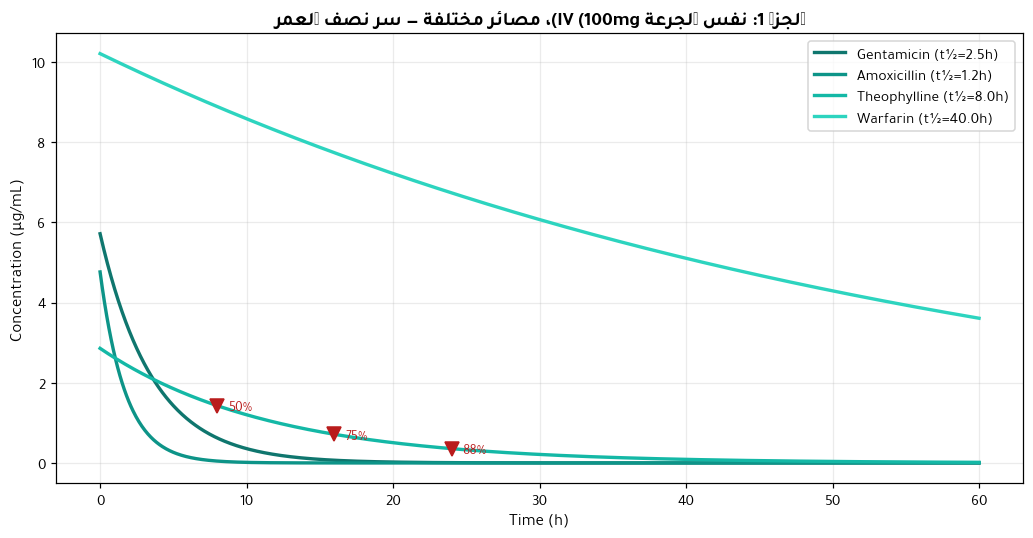

💡 اقرأ الرسم كصيدلي:
• Warfarin (t½=40h): يبقى في الجسم ~8 أيام → لذلك جرعة واحدة يومية كافية، وتوقفه يحتاج أسابيع.
• Gentamicin (t½=2.5h): يختفي خلال ساعات → لذلك نكرره 3 مرات يومياً (أو نغير الاستراتيجية كلياً!).
• بعد 5 أنصاف عمر يتبقى أقل من 3% — القاعدة التي تحكم كل شيء قادمًا.


In [3]:
# ═══ الجزء 1: محاكاة IV — لماذا يغيّر نصف العمر كل شيء؟ ═══
t = np.linspace(0, 60, 1200)
sel = ['Gentamicin', 'Amoxicillin', 'Theophylline', 'Warfarin']

fig, ax = plt.subplots(figsize=(9.5, 5))
for i, d in enumerate(sel):
    r = DRUGS.loc[d]
    C = iv_bolus(100, r.Vd, r.k, t)
    ax.plot(t, C, color=TEAL[i], lw=2.2, label=f'{d} (t½={r.thalf}h)')

# علامات أنصاف العمر على منحنى الثيوفيلين: 50% ← 75% ← 87.5%
r = DRUGS.loc['Theophylline']
for n, frac in enumerate([0.5, 0.75, 0.875]):
    tn = (n + 1) * r.thalf
    cn = iv_bolus(100, r.Vd, r.k, np.array([tn]))[0]
    ax.plot(tn, cn, 'v', color='#B91C1C', ms=9)
    ax.annotate(f'{frac:.0%}', (tn, cn), xytext=(7, -3),
                textcoords='offset points', fontsize=9, color='#B91C1C')

ax.set(xlabel='Time (h)', ylabel='Concentration (µg/mL)',
       title=ar('الجزء 1: نفس الجرعة IV (100mg)، مصائر مختلفة — سر نصف العمر'))
ax.legend()
plt.tight_layout(); plt.show()

print("""💡 اقرأ الرسم كصيدلي:
• Warfarin (t½=40h): يبقى في الجسم ~8 أيام → لذلك جرعة واحدة يومية كافية، وتوقفه يحتاج أسابيع.
• Gentamicin (t½=2.5h): يختفي خلال ساعات → لذلك نكرره 3 مرات يومياً (أو نغير الاستراتيجية كلياً!).
• بعد 5 أنصاف عمر يتبقى أقل من 3% — القاعدة التي تحكم كل شيء قادمًا.""")


---
## الجزء 2 — الإعطاء الفموي: معادلة باتيمان (Bateman)

عند تناول الدواء فموياً يتنافس عمليان من الدرجة الأولى: **الامتصاص** (ثابت $k_a$) و**الإطراح** (ثابت $k$). حل المعادلتين التفاضليتين يعطي منحنى «الصعود ثم الهبوط» الشهير:

$$C(t) = \frac{F \cdot D \cdot k_a}{V_d\,(k_a - k)}\left(e^{-kt} - e^{-k_a t}\right)$$

- **$F$ — التوافر الحيوي:** الكسر الذي يصل الدواء به إلى الدورة الجهازية فعلياً (الامتصاص + تأثير المرور الكبدي الأول).
- **$k_a$ — ثابت الامتصاص:** كلما كبر، صعد المنحنى أسرع وبلغ الذروة مبكراً — حتى لو بقيت الـ $AUC$ (المساحة = الكمية الممتصة كلها) ثابتة!
- **زمن الذروة التحليلي:** $T_{max} = \dfrac{\ln(k_a/k)}{k_a - k}$
- **ظاهرة Flip-Flop:** إذا صار الامتصاص *أبطأ* من الإطراح ($k_a < k$) انقلب المنحنى: يصبح الامتصاص هو المحدِّد لطرف الهبوط — هذا سر تركيبات طويلة المفعول الفموية.

> 💡 لاحظ مبدأً سيغيّر تفكيرك: **$F$ و $k_a$ يغيّران شكل المنحنى لا مساحته الكلية** — الكمية التي تصل واحدة، لكن *السرعة* تتغير، ومعها الذروة، ومعها السمّية الفورية.

/tmp/ipykernel_1704/3140765094.py:33: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return float(C[i]), float(t[i]), float(np.trapz(C, t))
/tmp/ipykernel_1704/2197851994.py:25: UserWarning: Glyph 65265 (\N{ARABIC LETTER YEH ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2197851994.py:25: UserWarning: Glyph 65209 (\N{ARABIC LETTER SAD ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2197851994.py:25: UserWarning: Glyph 65165 (\N{ARABIC LETTER ALEF ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2197851994.py:25: UserWarning: Glyph 65155 (\N{ARABIC LETTER ALEF WITH HAMZA ABOVE ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()


/tmp/ipykernel_1704/2197851994.py:25: UserWarning: Glyph 65193 (\N{ARABIC LETTER DAL ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2197851994.py:25: UserWarning: Glyph 65171 (\N{ARABIC LETTER TEH MARBUTA ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/home/z/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65265 (\N{ARABIC LETTER YEH ISOLATED FORM}) missing from font(s) Tajawal.
  fig.canvas.print_figure(bytes_io, **kw)
/home/z/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65209 (\N{ARABIC LETTER SAD ISOLATED FORM}) missing from font(s) Tajawal.
  fig.canvas.print_figure(bytes_io, **kw)
/home/z/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65155 (\N{ARABIC LETTER ALEF WITH HAMZA ABOVE ISOLATED FORM}) missing from font(s) Tajawal.
  fig.canvas.print_figure(bytes_io, **kw)
/home/z/.venv/li

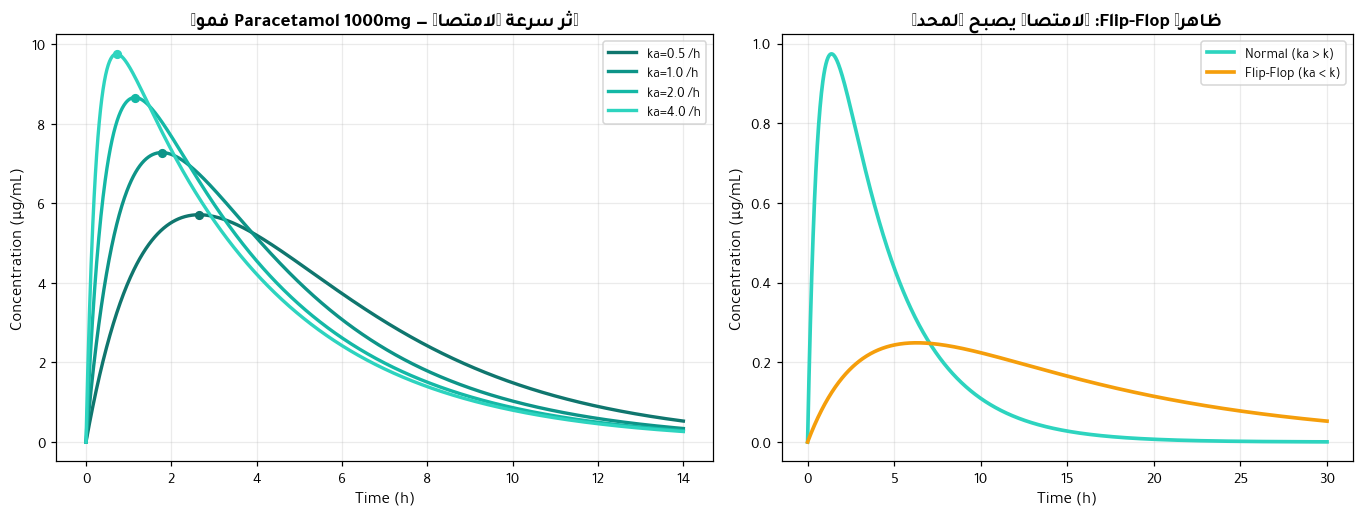

📊 Paracetamol 1000mg (ka=2/h): Cmax = 8.7 µg/mL | Tmax = 1.15 h | AUC₀₋₁₄ = 42 µg·h/mL
🧮 Tmax التحليلي = ln(ka/k)/(ka-k) = 1.15 h  ← مطابقة شبه تامة مع المحاكاة!
💡 لاحظ: ka تغيّر الذروة والزمن لكن AUC (الكمية الكلية الممتصة) لا تتغير تقريباً — السرعة ليست الكمية.


In [4]:
# ═══ الجزء 2: الإعطاء الفموي — باتيمان، Cmax/Tmax، وFlip-Flop ═══
r = DRUGS.loc['Paracetamol']
t = np.linspace(0, 14, 1400)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={'width_ratios': [1.15, 1]})

# (أ) أثر سرعة الامتصاص ka على الشكل — مع علامة الذروة لكل منحنى
for i, ka in enumerate([0.5, 1.0, 2.0, 4.0]):
    C = oral_bateman(1000, r.F, ka, r.k, r.Vd, t)
    cmax, tmax, _ = pk_metrics(t, C)
    axes[0].plot(t, C, color=TEAL[i], lw=2.2, label=f'ka={ka} /h')
    axes[0].plot(tmax, cmax, 'o', color=TEAL[i], ms=5)
axes[0].set(xlabel='Time (h)', ylabel='Concentration (µg/mL)',
            title=ar('أثر سرعة الامتصاص — Paracetamol 1000mg فموي'))
axes[0].legend(fontsize=9)

# (ب) ظاهرة Flip-Flop: ka أبطأ من k
t2 = np.linspace(0, 30, 1500)
for i, (ka, lab) in enumerate([(1.5, 'Normal (ka > k)'), (0.08, 'Flip-Flop (ka < k)')]):
    C = oral_bateman(100, 0.9, ka, r.k, r.Vd, t2)
    axes[1].plot(t2, C, color=TEAL[i + 3], lw=2.4, label=lab)
axes[1].set(xlabel='Time (h)', ylabel='Concentration (µg/mL)',
            title=ar('ظاهرة Flip-Flop: الامتصاص يصبح المحدِّد'))
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

# قياسات باراسيتامول 1000mg بـ ka=2 + التحقق التحليلي
Cmax, Tmax, AUC = pk_metrics(t, oral_bateman(1000, r.F, 2.0, r.k, r.Vd, t))
tmax_theory = np.log(2.0 / r.k) / (2.0 - r.k)
print(f'📊 Paracetamol 1000mg (ka=2/h): Cmax = {Cmax:.1f} µg/mL | Tmax = {Tmax:.2f} h | AUC₀₋₁₄ = {AUC:.0f} µg·h/mL')
print(f'🧮 Tmax التحليلي = ln(ka/k)/(ka-k) = {tmax_theory:.2f} h  ← مطابقة شبه تامة مع المحاكاة!')
print('💡 لاحظ: ka تغيّر الذروة والزمن لكن AUC (الكمية الكلية الممتصة) لا تتغير تقريباً — السرعة ليست الكمية.')


---
## الجزء 3 — الجرعات المتكررة: التراكم والحالة المستقرة

في الواقع الإكليني لا نأخذ جرعة واحدة. نكرر الجرعة كل $\tau$ ساعة، فتتراكب الجرعات حسب **مبدأ التراكب (Superposition)**: التركيز الكلي = مجموع آثار كل جرعة سابقة.

$$R_{ac} = \frac{1}{1 - e^{-k\tau}}$$

- كلما قصرت فترة الجرعة $\tau$ نسبةً إلى $t_{1/2}$، **تراكم أعلى** وذروة أعلى.
- بلوغ **الحالة المستقرة (Steady State)** يحتاج ~5 أنصاف عمر *بغضّ النظر* عن الجدول — لا يمكن «تسريعها» بتكرار الجرعة، بل فقط بجرعة تحميلية.
- عند الاستقرار تتأرجح التركيزات بين **ذروة ($C_{ss,max}$)** وقاع ($C_{ss,min}$) في نطاق شبه ثابت.

> 🎯 سؤال التصميم الجرعي كله: اختر $(D, \tau)$ بحيث يبقى هذا التأرجح **داخل النافذة العلاجية** — وهذا بالضبط ما سبرمجه الجزءان 3 و4.

/tmp/ipykernel_1704/2610428023.py:19: UserWarning: Glyph 65155 (\N{ARABIC LETTER ALEF WITH HAMZA ABOVE ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2610428023.py:19: UserWarning: Glyph 65165 (\N{ARABIC LETTER ALEF ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2610428023.py:19: UserWarning: Glyph 65171 (\N{ARABIC LETTER TEH MARBUTA ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2610428023.py:19: UserWarning: Glyph 65152 (\N{ARABIC LETTER HAMZA ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()


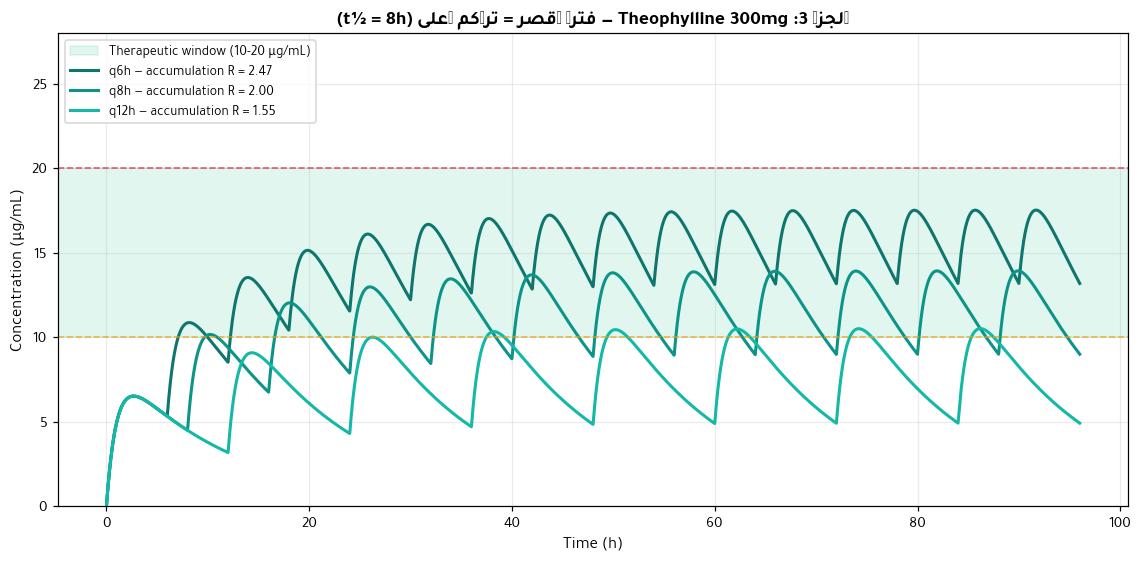

⏱️ الحالة المستقرة (~5 أنصاف عمر) بعد ≈ 40 ساعة لهذا الدواء — أياً كان الجدول!
💡 q6h: تراكم 2.5× وذروة داخل النافذة | q12h: تراكم قليل لكن المتوسط تحت MEC = فشل علاجي محتمل


In [5]:
# ═══ الجزء 3: الجرعات المتكررة — التراكم والحالة المستقرة ═══
r = DRUGS.loc['Theophylline']
D = 300
fig, ax = plt.subplots(figsize=(10.5, 5.2))

ax.axhspan(10, 20, color='#10B981', alpha=0.12, label='Therapeutic window (10-20 µg/mL)')
for i, tau in enumerate([6, 8, 12]):
    t, C = repeated(D, r.F, r.ka, r.k, r.Vd, tau, 96, 'oral')
    R_acc = 1 / (1 - np.exp(-r.k * tau))
    ax.plot(t, C, color=TEAL[i], lw=2.0,
            label=f'q{tau}h — accumulation R = {R_acc:.2f}')

ax.axhline(20, color='#E11D48', ls='--', lw=1.1, alpha=0.7)
ax.axhline(10, color='#F59E0B', ls='--', lw=1.1, alpha=0.7)
ax.set(xlabel='Time (h)', ylabel='Concentration (µg/mL)',
       title=ar(f'الجزء 3: Theophylline {D}mg — فترة أقصر = تراكم أعلى (t½ = {r.thalf:.0f}h)'))
ax.set_ylim(0, 28)
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

print(f'⏱️ الحالة المستقرة (~5 أنصاف عمر) بعد ≈ {5 * r.thalf:.0f} ساعة لهذا الدواء — أياً كان الجدول!')
print('💡 q6h: تراكم 2.5× وذروة داخل النافذة | q12h: تراكم قليل لكن المتوسط تحت MEC = فشل علاجي محتمل')


---
## الجزء 4 — النافذة العلاجية: من الرسم إلى القرار

النافذة العلاجية هي المدى بين **أقل تركيز فعّال (MEC)** و**أقل تركيز سام (MSC)**. خارجها إما فشل علاجي أو سمّية. سنكتب دالة `clinical_report()` تحاكي أي جدول جرعي ثم تحكم عليه:

- ما نسبة الزمن داخل النافذة؟ فوقها (خطر)؟ تحتها (فشل)؟
- ما الذروة والقاع عند الاستقرار؟
- الحكم: 🟢 آمن وفعّال / 🟠 يحتاج ضبطاً / 🔴 خطر سمّي

> ⚠️ **حدود الدليل — عقلية الصيدلي الناقد:** القاعدة العامة «أبقِ التركيز داخل النافذة» لا تنطبق حرفياً على كل دواء! الجنتامايسين مثلاً *نريد* قاعه تحت 2 µg/mL عمداً — لأن تراكمه في الأذن والكلى هو مصدر سمّيته — ومن هنا وُلدت استراتيجية **الجرعة العالية المتباعدة**. الدالة البرمجية أداة قرار مساعدة، والفارماكولوجي السريري هو من يقرر متى نخرق القاعدة العامة.

🟠 يحتاج ضبطاً | Gentamicin 120mg q8h (IV) → Peak=7.67 · Trough=0.83 µg/mL | داخل النافذة 58% · فوقها 0% · تحتها 42%
🟢 آمن وفعّال | Digoxin 0.25mg q24h (ORAL) → Peak=0.87 · Trough=0.62 ng/mL | داخل النافذة 100% · فوقها 0% · تحتها 0%


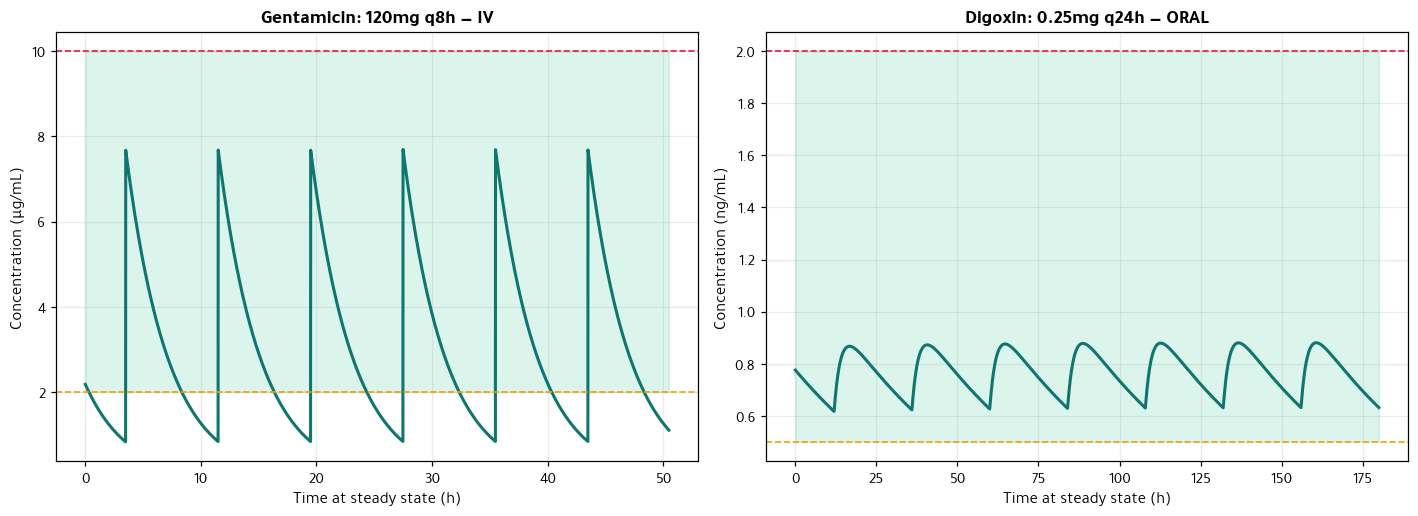

⚠️ عقلية الصيدلي الناقد: Gentamicin صُنّف «يحتاج ضبطاً» لأن قاعه تحت MEC — لكن هذا مطلوب عمداً!
   للأمينوغليكوزيدات نريد قاعاً منخفضاً لمنع التراكم السمّي في الأذن والكلية → الجرعة العالية المتباعدة.
   Digoxin 0.25mg يومياً: ذروة ≈ 0.9 ng/mL وقاع ≈ 0.5 ng/mL (النافذة 0.5–2) → استقرار مثالي.
   الدالة أداة مساعدة للقرار، والفارماكولوجي السريري هو من يقرر متى نخرق القاعدة العامة.


In [6]:
# ═══ الجزء 4: النافذة العلاجية — دالة القرار الإكليني ═══
def clinical_report(drug, D, tau, route, t_max=None, scale=1.0, unit='µg/mL'):
    """تحاكي جدولاً جرعياً وتصدر حكماً: آمن / يحتاج ضبطاً / خطر سمّي (scale لتحويل الوحدة)"""
    r = DRUGS.loc[drug]
    if t_max is None:
        t_max = 6 * r.thalf + 6 * tau
    t, C = repeated(D, r.F, r.ka, r.k, r.Vd, tau, t_max, route)
    ss = t > 5 * r.thalf                    # نحلل فقط ما بعد الاستقرار
    t_ss = t[ss] - t[ss].min()
    C_ss = C[ss]
    cyc = t_ss < tau                        # أول دورة جرعية مستقرة
    C_sc = C_ss * scale                     # الوحدة المعروضة
    peak, trough = float(C_sc[cyc].max()), float(C_sc[cyc].min())
    lo, hi = r.win_low * scale, r.win_high * scale
    frac_in  = float(np.mean((C_sc >= lo) & (C_sc <= hi)) * 100)
    frac_tox = float(np.mean(C_sc > hi) * 100)
    frac_sub = float(np.mean(C_sc < lo) * 100)
    if frac_tox < 5 and frac_in >= 70:
        verdict = '🟢 آمن وفعّال'
    elif frac_tox > 10:
        verdict = '🔴 خطر سمّي'
    else:
        verdict = '🟠 يحتاج ضبطاً'
    print(f'{verdict} | {drug} {D}mg q{tau}h ({route.upper()}) → '
          f'Peak={peak:.2f} · Trough={trough:.2f} {unit} | '
          f'داخل النافذة {frac_in:.0f}% · فوقها {frac_tox:.0f}% · تحتها {frac_sub:.0f}%')
    return t_ss, C_sc, lo, hi

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
cases = [('Gentamicin', 120, 8, 'iv', 1.0, 'µg/mL'),
         ('Digoxin', 0.25, 24, 'oral', 1000.0, 'ng/mL')]
for ax, (drug, D, tau, route, scale, unit) in zip(axes, cases):
    t_ss, C_ss, lo, hi = clinical_report(drug, D, tau, route, scale=scale, unit=unit)
    ax.fill_between(t_ss, lo, hi, color='#10B981', alpha=0.15)
    ax.plot(t_ss, C_ss, color='#0F766E', lw=2.0)
    ax.axhline(hi, color='#E11D48', ls='--', lw=1.1)
    ax.axhline(lo, color='#F59E0B', ls='--', lw=1.1)
    ax.set(xlabel='Time at steady state (h)', ylabel=f'Concentration ({unit})',
           title=ar(f'{drug}: {D}mg q{tau}h — {route.upper()}'))
plt.tight_layout(); plt.show()

print('⚠️ عقلية الصيدلي الناقد: Gentamicin صُنّف «يحتاج ضبطاً» لأن قاعه تحت MEC — لكن هذا مطلوب عمداً!')
print('   للأمينوغليكوزيدات نريد قاعاً منخفضاً لمنع التراكم السمّي في الأذن والكلية → الجرعة العالية المتباعدة.')
print('   Digoxin 0.25mg يومياً: ذروة ≈ 0.9 ng/mL وقاع ≈ 0.5 ng/mL (النافذة 0.5–2) → استقرار مثالي.')
print('   الدالة أداة مساعدة للقرار، والفارماكولوجي السريري هو من يقرر متى نخرق القاعدة العامة.')


---
## الجزء 5 — حالة 2026: Foundayo (Orforglipron) — لماذا «فموي» يغيّر قواعد اللعبة؟

📌 **تحديث 2026:** في 1 أبريل 2026 وافقت FDA على **Orforglipron (Foundayo)** — أول ناهض GLP-1 **فموي غير ببتيدي** في التاريخ (ملف NDA 220934، عبر مسار CNPV السريع). وأيضاً: **Enlicitide (Lipfendra)** أصبح في 16 يوليو 2026 أول مثبط PCSK9 فموي، بخفض LDL-C بنسبة 56–59% في الطور الثالث (بدون إثبات لخفض الأحداث القلبية الكبرى MACE بعد — راجع صندوق «حدود الدليل» في الفصل 12).

**السؤال الفارماكوكينيتيكي:** الببتيدات مثل Semaglutide تُحقن أسبوعياً لأنها تتفكك هضمياً إن نُولعت. الجزيء الصغير الفموي يحتاج $t_{1/2}$ يدعم الجرعة **مرة يومياً** بالحبوب. لنجارِ بالمحاكاة (تقريبية تعليمية) بين:

1. جزيء فموي يومي: $t_{1/2} \approx 30$ ساعة ← يبلغ 95% من الحالة المستقرة خلال **~6 أيام**.
2. ببتيد حقني أسبوعي: $t_{1/2} \approx 7$ أيام ← يحتاج **~5 أسابيع** للاستقرار.

> ⚠️ **تنبيه منهجي:** بارامترات هذا الجزء **افتراضية تعليمية** وليست من النشرة الدوائية الرسمية؛ الهدف تدريب «عقلية المحاكي» التي تستخدمها شركات الأدوية فعلاً في تصاميم الجرعات قبل التجارب.

/tmp/ipykernel_1704/2302067233.py:27: UserWarning: Glyph 65165 (\N{ARABIC LETTER ALEF ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2302067233.py:27: UserWarning: Glyph 65171 (\N{ARABIC LETTER TEH MARBUTA ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2302067233.py:27: UserWarning: Glyph 65197 (\N{ARABIC LETTER REH ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2302067233.py:27: UserWarning: Glyph 65233 (\N{ARABIC LETTER FEH ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2302067233.py:27: UserWarning: Glyph 65155 (\N{ARABIC LETTER ALEF WITH HAMZA ABOVE ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_1704/2302067233.py:27: UserWarning: Glyph 65152 (\N{ARABIC LETTER HAMZA ISOLATED FORM}) missing from font(s) Tajawal.
  plt.tight_layout()

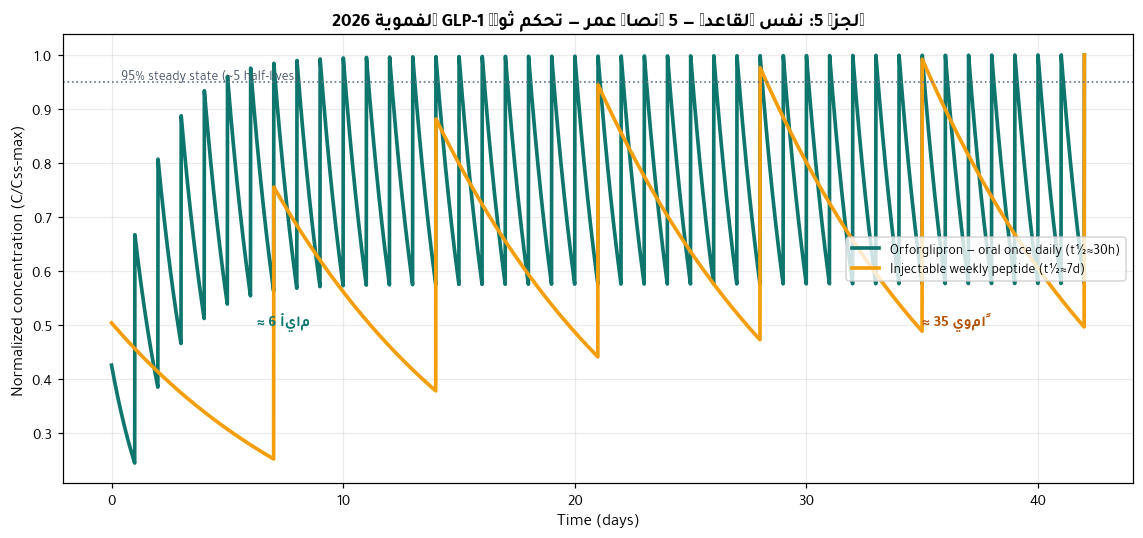

📌 خلاصة الحالة (Orforglipron, FDA 2026-04-01 · Enlicitide, FDA 2026-07-16):
• نفس معادلات الفصل 2 التي برمجتَها للتو تُستخدم اليوم لتصميم «حبة يومية» لجزيئات كانت مستحيلة فموياً.
• t½≈30h يجعل الجرعة اليومية ممكنة، والاستقرار خلال ~6 أيام يبرر بروتوكولات المعايرة التدريجية.
• Enlicitide خفض LDL-C بنسبة 56-59% فموياً — لكن MACE غير مثبت بعد: فعالية بديلة (surrogate) ليست نتيجة قلبية.
⚠️ الأرقام هنا افتراضية تعليمية؛ القرار الحقيقي يحتاج النشرة الرسمية والشروط المرضية الفعلية.


In [7]:
# ═══ الجزء 5: حالة 2026 — فموي يومي مقابل حقن أسبوعي (نموذج تعليمي) ═══
# ⚠️ بارامترات افتراضية تعليمية — ليست من النشرة الرسمية
def ss_profile(thalf_h, tau_h, days):
    """بروفيل التجميع المُطبَّع حتى الحالة المستقرة (يوضح زمن بلوغها فقط)"""
    k = np.log(2) / thalf_h
    t = np.linspace(0, days * 24, 5000)
    C = np.zeros_like(t)
    for n in range(int(days * 24 // tau_h) + 1):
        m = t >= n * tau_h
        C[m] += np.exp(-k * (t[m] - n * tau_h))
    return t / 24, C / C.max()

fig, ax = plt.subplots(figsize=(10.5, 5))
for lab, th, tau, c in [('Orforglipron — oral once daily (t½≈30h)', 30, 24, '#0F766E'),
                        ('Injectable weekly peptide (t½≈7d)', 168, 168, '#F59E0B')]:
    x, C = ss_profile(th, tau, 42)
    ax.plot(x, C, color=c, lw=2.4, label=lab)

ax.axhline(0.95, color='#64748B', ls=':', lw=1.1)
ax.annotate('95% steady state (~5 half-lives)', xy=(0.4, 0.955),
            fontsize=9, color='#475569')
ax.annotate('≈ 6 أيام', xy=(6.3, 0.5), fontsize=10, color='#0F766E', fontweight='bold')
ax.annotate('≈ 35 يوماً', xy=(35, 0.5), fontsize=10, color='#B45309', fontweight='bold')
ax.set(xlabel='Time (days)', ylabel='Normalized concentration (C/Css-max)',
       title=ar('الجزء 5: نفس القاعدة — 5 أنصاف عمر — تحكم ثورة GLP-1 الفموية 2026'))
ax.legend(loc='center right', fontsize=9)
plt.tight_layout(); plt.show()

print("""📌 خلاصة الحالة (Orforglipron, FDA 2026-04-01 · Enlicitide, FDA 2026-07-16):
• نفس معادلات الفصل 2 التي برمجتَها للتو تُستخدم اليوم لتصميم «حبة يومية» لجزيئات كانت مستحيلة فموياً.
• t½≈30h يجعل الجرعة اليومية ممكنة، والاستقرار خلال ~6 أيام يبرر بروتوكولات المعايرة التدريجية.
• Enlicitide خفض LDL-C بنسبة 56-59% فموياً — لكن MACE غير مثبت بعد: فعالية بديلة (surrogate) ليست نتيجة قلبية.
⚠️ الأرقام هنا افتراضية تعليمية؛ القرار الحقيقي يحتاج النشرة الرسمية والشروط المرضية الفعلية.""")


---
## 🎯 تمارين المختبر 01

حاول الحل بالورقة أولاً، ثم تحقق بالكود (خلايا الحلول في الأسفل).

**تمرين 1 — أساسيات:** دواء عمره النصف 6 ساعات، حجم توزيعه 0.8 L/kg، ومريضه 70 كغ. احسب $k$ و $V_d$ و $CL$.

**تمرين 2 — الذروة التحليلية:** باراسيتامول بـ $k_a = 2\,h^{-1}$ و $k = 0.277\,h^{-1}$. احسب $T_{max}$ بالصيغة التحليلية، ثم قارنها بنتيجة المحاكاة العددية (`argmax`). ماذا تعني المطابقة؟

**تمرين 3 — تصميم جدول جرعي:** ثيوفيلين 300 mg لكل جرعة. جرّب فترات $\tau = 6, 8, 12$ ساعة. أي جدول يُبقي **متوسط** التركيز عند الاستقرار داخل نافذة 10–20 µg/mL؟ (تلميح نظري: $\bar{C}_{ss} = \dfrac{F \cdot D}{CL \cdot \tau}$)

**🏆 التحدي — الجرعة التحميلية:** اضرب الحسابات: ما الجرعة التحميلية للديجوكسين للوصول فوراً إلى ذروة 1.4 ng/mL؟ ولماذا تُعطى إكلينياً على جرعات مجزأة عبر 24 ساعة رغم أن الصيغة تعطي رقماً واحداً؟ (فكّر: $LD = \dfrac{C_{target} \cdot V_d}{F}$ — وماذا يحدث لو وصلت الذروة دفعة واحدة؟)

---
## ✅ الحلول — حاول بنفسك أولاً!

In [8]:
# ═══ ✅ الحلول — قارن مع محاولتك ═══
print('── تمرين 1 ──')
th, vd_kg = 6.0, 0.8
k1 = np.log(2) / th
Vd1 = vd_kg * BW
CL1 = k1 * Vd1
print(f'k = ln2/6 = {k1:.4f} h⁻¹ | Vd = 0.8×70 = {Vd1:.0f} L | CL = k·Vd = {CL1:.2f} L/h')

print('── تمرين 2 ──')
ka2, k2 = 2.0, np.log(2) / 2.5
tmax_analytic = np.log(ka2 / k2) / (ka2 - k2)
t_grid = np.linspace(0, 6, 6000)
C2 = oral_bateman(1000, 0.75, ka2, k2, 0.9 * BW, t_grid)
print(f'Tmax تحليلياً = {tmax_analytic:.2f} h | بالمحاكاة العددية = {t_grid[np.argmax(C2)]:.2f} h')
print('المطابقة تعني: النموذج الرياضي والكود يصفان الحقيقة نفسها — المحاكاة مجرد «حل بصري» للمعادلة.')

print('── تمرين 3 ──')
r = DRUGS.loc['Theophylline']
for tau in [6, 8, 12]:
    t3, C3 = repeated(300, r.F, r.ka, r.k, r.Vd, tau, 240, 'oral')
    ss3 = C3[t3 > 5 * r.thalf].mean()
    css_theory = r.F * 300 / (r.CL * tau)
    ok = '✅ مناسب' if 10 <= ss3 <= 20 else '❌ غير مناسب'
    print(f'q{tau}h → متوسط الاستقرار ≈ {ss3:.1f} µg/mL (نظرياً F·D/CL/τ = {css_theory:.1f}) {ok}')

print('── 🏆 التحدي: الجرعة التحميلية للديجوكسين ──')
r = DRUGS.loc['Digoxin']
Ctarget = 1.4 / 1000          # 1.4 ng/mL = 0.0014 µg/mL
LD = Ctarget * r.Vd / r.F
print(f'LD = C_target·Vd/F = {Ctarget:.4f}×{r.Vd:.0f}/{r.F:.2f} = {LD:.2f} mg')
print('إكلينياً تُعطى 0.75–1.5mg مجزأة عبر 24h: لو وصلت الذروة دفعة واحدة لاختلفت الذروة الوعائية الأولى')
print('واقتربت من نطاق السمّية — الجرعة التحميلية المجزأة = الوصول للهدف عبر بوابات أمان زمنية.')


── تمرين 1 ──
k = ln2/6 = 0.1155 h⁻¹ | Vd = 0.8×70 = 56 L | CL = k·Vd = 6.47 L/h
── تمرين 2 ──
Tmax تحليلياً = 1.15 h | بالمحاكاة العددية = 1.15 h
المطابقة تعني: النموذج الرياضي والكود يصفان الحقيقة نفسها — المحاكاة مجرد «حل بصري» للمعادلة.
── تمرين 3 ──
q6h → متوسط الاستقرار ≈ 15.8 µg/mL (نظرياً F·D/CL/τ = 15.8) ✅ مناسب
q8h → متوسط الاستقرار ≈ 11.9 µg/mL (نظرياً F·D/CL/τ = 11.9) ✅ مناسب
q12h → متوسط الاستقرار ≈ 7.9 µg/mL (نظرياً F·D/CL/τ = 7.9) ❌ غير مناسب
── 🏆 التحدي: الجرعة التحميلية للديجوكسين ──
LD = C_target·Vd/F = 0.0014×490/0.70 = 0.98 mg
إكلينياً تُعطى 0.75–1.5mg مجزأة عبر 24h: لو وصلت الذروة دفعة واحدة لاختلفت الذروة الوعائية الأولى
واقتربت من نطاق السمّية — الجرعة التحميلية المجزأة = الوصول للهدف عبر بوابات أمان زمنية.


---
## 📌 خلاصة المختبر 01 — جدول «المفهوم ← السطر البرمجي»

| المفهوم النظري (الفصل 2) | ترجمته البرمجية |
|---|---|
| ثابت الإطراح $k$ | `k = np.log(2) / thalf` |
| التركيز الابتدائي $C_0$ | `C0 = D / Vd` |
| مسار IV | `C0 * np.exp(-k * t)` |
| مسار فموي | معادلة باتيمان (سطر واحد) |
| $C_{max}$، $T_{max}$، $AUC$ | `argmax` + `np.trapz` |
| تراكم الجرعات | حلقة تراكب + $R = 1/(1-e^{-k\tau})$ |
| الحالة المستقرة | قناع زمني `t > 5*t½` |
| النافذة العلاجية | قناع منطقي `(C >= low) & (C <= high)` |
| قرار إكليني | دالة تُرجع: آمن / ضبط / سمّي |

### ماذا تعلمنا عن «الكتاب الحي»؟
لم تكن هذه محاضرة تُقرأ، بل **مختبراً يُشغَّل**: عدّلت بارامترات، فسّرت منحنيات، وحكمت على جداول جرعية. نفس الدورة — نظرية ← كود ← قرار — سنكررها في كل مختبر.

### ⏭️ المختبر القادم (02)
**فارماكوديناميك: «ما يفعله الدواء بالجسم»** — منحنى الجرعة–الاستجابة، $E_{max}$ و $EC_{50}$ ومعامل هيل، الناهض الكامل والجزئي والمضاد التنافسي وغير التنافسي… بنفس الأسلوب: معادلة ← دالة ← رسم ← قرار.